# 05 · Fitur Unik 1: Interval Prediksi (*Conformal Prediction*)
## Estimasi Harga Rumah California dengan MLP Regresi

Model MLP mengeluarkan **satu angka** (misalnya \$250.000). Fitur ini mengubahnya menjadi **rentang dengan jaminan cakupan**:
*"dengan keyakinan 90%, median harga rumah di blok ini ada di antara \$X dan \$Y"*. Rentang itu dihitung dengan *split conformal prediction*,
tanpa melatih ulang model dan tanpa asumsi bentuk distribusi galat.

### Pemetaan ke ketentuan fitur unik

| Unsur yang diminta | Bagian |
|---|---|
| Apa fiturnya | 1 |
| Mengapa dibutuhkan | 2 |
| Bagaimana implementasinya | 3 (metode, pemilihan metode, penyimpanan untuk aplikasi) |
| Bukti dampaknya | 4 (cakupan, kalibrasi, cakupan per kelompok, kestabilan, contoh) |

### Protokol

| # | Aturan | Alasan |
|---|---|---|
| 1 | Kalibrasi memakai **validation**; evaluasi memakai **test** | Test tidak boleh ikut menentukan apa pun |
| 2 | Metode interval dipilih **hanya dari validation** (dibagi dua), dengan aturan yang ditulis sebelum melihat test | Menghindari memilih metode karena kebetulan bagus di test |
| 3 | Pembanding: interval "naif" `prediksi ± 1,645 × RMSE` | Memperlihatkan apa yang didapat dengan dan tanpa conformal |
| 4 | Hasil dikuantifikasi dengan **selang kepercayaan** cakupan dan **pembagian ulang acak** | Cakupan dari satu pembagian data punya ketidakpastian sendiri |

## 0. Setup

In [1]:
import hashlib
import json
import math
import os
import subprocess
import sys
import warnings
from datetime import date
from pathlib import Path
from statistics import NormalDist

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
ALPHA = 0.10               # tingkat kesalahan: interval 90% (cakupan target = 1 - ALPHA)
MODEL_SOURCE = "backend"   # "backend": model yang dipakai aplikasi | "notebook03": model dari notebook 03
RUN_MC = True              # True: ikutkan metode MC-Dropout (butuh model.__call__(training=True))
MC_T = 50                  # jumlah lintasan MC-Dropout
N_REPEAT = 200             # jumlah pembagian ulang acak pada uji kestabilan
TOL_COND = 0.05            # toleransi penyimpangan cakupan per kelompok prediksi (aturan pemilihan metode)
TARGET_SCALE = 100_000.0
TARGET = "median_house_value"

IN_COLAB = "google.colab" in sys.modules
REPO_NAME = "california-house-price-mlp"
REPO_URL = f"https://github.com/lukito789/{REPO_NAME}.git"

if IN_COLAB:
    ROOT = Path("/content") / REPO_NAME
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
else:
    ROOT = Path.cwd()
    if not (ROOT / "data" / "housing.csv").exists():
        ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "housing.csv"
PROC_PATH = ROOT / "data" / "processed" / "housing_processed.npz"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "data" / "processed"
for d_ in (FIG_DIR, MODEL_DIR):
    d_.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


if not PROC_PATH.exists():
    raise FileNotFoundError("housing_processed.npz belum ada. Jalankan 02_preprocessing.ipynb dan commit data/processed/.")
d = np.load(PROC_PATH, allow_pickle=True)
X_train, X_val, X_test = d["X_train"], d["X_val"], d["X_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"]
print(f"X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}")
print(f"Keras {keras.__version__} | interval {int((1 - ALPHA) * 100)}% | MC-Dropout: {RUN_MC}")

X_train (14447, 13) | X_val (3096, 13) | X_test (3097, 13)
Keras 3.13.2 | interval 90% | MC-Dropout: True


## 1. Apa Fiturnya

**Interval prediksi** adalah rentang `[bawah, atas]` di sekitar prediksi MLP yang disertai jaminan:

> Jika data kalibrasi dan data baru berasal dari distribusi yang sama, maka rentang dengan tingkat 90% memuat harga sebenarnya
> pada **sedikitnya 90%** kasus.

**Cara kerjanya, secara ringkas** (*split conformal prediction*):

1. Sisihkan data yang **tidak dipakai melatih** model (di sini: validation, 3.096 blok) sebagai data kalibrasi.
2. Untuk tiap blok kalibrasi, hitung **skor ketidaksesuaian**: seberapa jauh prediksi meleset, sesudah dinormalkan dengan sebuah skala.
3. Ambil **kuantil ke-90%** dari skor itu (dengan koreksi sampel hingga), sebut `q`.
4. Untuk blok baru: interval = `prediksi ± q × skala`.

Jaminan ini berlaku pada **cakupan rata-rata** (*marginal*), bukan otomatis di setiap kelompok. Karena itu bagian 3 dan 4 memeriksa
cakupan per kelompok juga, bukan hanya angka keseluruhan.

**Tiga pilihan skala** (yang menentukan bentuk intervalnya):

| Metode | Skala | Bentuk interval |
|---|---|---|
| `absolut` | 1 | Lebar tetap `±q` dolar untuk semua blok |
| `relatif` | harga prediksi | Lebar sebanding harga: `±q × prediksi` |
| `mc_dropout` | simpangan baku prediksi MC-Dropout | Lebar mengikuti keraguan model sendiri |

## 2. Mengapa Dibutuhkan

Satu angka prediksi menyembunyikan seberapa besar model bisa meleset. Bagian ini mengukurnya pada data **validation** (test belum
disentuh), dikelompokkan menurut **harga prediksi**, karena itulah yang dilihat pengguna aplikasi.

In [2]:
# ----- Model: muat yang sudah ada; jika gagal (mis. beda versi Keras), latih ulang konfigurasi notebook 03 -----------
def train_baseline():
    keras.utils.set_random_seed(SEED)
    reg = regularizers.l2(1e-4)
    model = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(128, activation="relu", kernel_regularizer=reg), layers.Dropout(0.2),
        layers.Dense(64, activation="relu", kernel_regularizer=reg), layers.Dropout(0.2),
        layers.Dense(32, activation="relu", kernel_regularizer=reg),
        layers.Dense(1, activation="linear"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=64, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True),
                         keras.callbacks.ReduceLROnPlateau(patience=8, factor=0.5, min_lr=1e-5)])
    return model
# ------------------------------------------------------------------------------------------------------------------

CANDIDATES = {"backend": ROOT / "backend" / "artifacts" / "model.keras",
              "notebook03": ROOT / "data" / "processed" / "mlp_notebook03.keras"}
model, model_path, model_key = None, None, None
for key in [MODEL_SOURCE] + [k for k in CANDIDATES if k != MODEL_SOURCE]:
    p = CANDIDATES[key]
    if not p.exists():
        print(f"[lewati] {p.relative_to(ROOT)} tidak ada")
        continue
    try:
        m = keras.models.load_model(p)
        if m.input_shape[-1] != X_train.shape[1]:
            raise ValueError(f"jumlah fitur model {m.input_shape[-1]} != data {X_train.shape[1]}")
        model, model_path, model_key = m, p, key
        break
    except Exception as err:
        print(f"[gagal]  {p.relative_to(ROOT)}: {type(err).__name__}: {str(err)[:90]}")

if model is None:
    print("Tidak ada model yang bisa dimuat. Melatih ulang dengan konfigurasi notebook 03 (beberapa menit)...")
    model = train_baseline()
    model_path, model_key = MODEL_DIR / "mlp_05_retrain.keras", "retrain"
    model.save(model_path)

model_sha = hashlib.sha256(Path(model_path).read_bytes()).hexdigest()
print(f"\nModel dipakai : {Path(model_path).relative_to(ROOT)}  (sumber: {model_key})")
print(f"SHA-256       : {model_sha[:16]}...")
if model_key != "backend":
    print("PERHATIAN: nilai q hanya berlaku untuk model ini. Agar valid di aplikasi, aplikasi harus memakai model yang sama.")

pred_val = model.predict(X_val, verbose=0).ravel().astype("float64")
pred_test = model.predict(X_test, verbose=0).ravel().astype("float64")

# Semua perhitungan berikutnya dalam USD
yv, pv = y_val.astype("float64") * TARGET_SCALE, pred_val * TARGET_SCALE
yt, pt = y_test.astype("float64") * TARGET_SCALE, pred_test * TARGET_SCALE


def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)


print(f"\nValidation: MAE ${np.mean(np.abs(pv - yv)):,.0f} | R2 {r2(yv, pv):.3f}")
print(f"Test      : MAE ${np.mean(np.abs(pt - yt)):,.0f} | R2 {r2(yt, pt):.3f}")
assert r2(yt, pt) > 0.5, "R2 test terlalu rendah: model tidak cocok dengan data (periksa preprocessing/model)."


Model dipakai : backend/artifacts/model.keras  (sumber: backend)
SHA-256       : c92019c4c5eaaebd...

Validation: MAE $31,779 | R2 0.820
Test      : MAE $33,021 | R2 0.821


In [3]:
ae = np.abs(pv - yv)
print(f"Galat absolut (validation): median ${np.median(ae):,.0f} | rata-rata ${ae.mean():,.0f} | "
      f"persentil 90 ${np.percentile(ae, 90):,.0f} | maks ${ae.max():,.0f}")

BIN_EDGES = [-np.inf, 100e3, 200e3, 300e3, 400e3, np.inf]
BIN_LABELS = ["<100k", "100-200k", "200-300k", "300-400k", ">=400k"]
grp = pd.cut(pv, BIN_EDGES, labels=BIN_LABELS)
tbl = (pd.DataFrame({"harga_prediksi": grp, "galat": ae})
         .groupby("harga_prediksi", observed=True)["galat"]
         .agg(jumlah="size", MAE="mean", persentil90=lambda s: np.percentile(s, 90)))
tbl["galat_>50k_%"] = (pd.DataFrame({"g": grp, "a": ae > 50_000}).groupby("g", observed=True)["a"].mean() * 100).values
display(tbl.round(0).astype({"jumlah": int}))

Galat absolut (validation): median $19,847 | rata-rata $31,779 | persentil 90 $71,477 | maks $381,078


,jumlah,MAE,persentil90,galat_>50k_%
harga_prediksi,,,,
<100k,466,14031.0,27620.0,3.0
100-200k,1315,27146.0,55426.0,13.0
200-300k,830,39023.0,83899.0,26.0
300-400k,296,55676.0,121030.0,43.0
>=400k,189,38529.0,77103.0,28.0


**Yang dilihat dari tabel:** besar galat **berbeda jauh antar kelompok harga**. Prediksi untuk rumah murah dan rumah mahal tidak sama
andalnya, padahal keduanya tampil sebagai satu angka yang tampak sama pasti. Pengguna butuh tahu *seberapa jauh angka itu boleh
dipercaya*, dan rentang dengan jaminan cakupan menjawabnya. Interval yang baik juga harus **menyesuaikan lebarnya**: sempit saat model
yakin, lebar saat model ragu.

## 3. Implementasi

### 3.1 Skor, kuantil, dan tiga metode

`conformal_q` memakai koreksi sampel hingga: dari `n` skor kalibrasi, diambil skor terurut ke-`⌈(n+1)(1−α)⌉`. Koreksi inilah yang memberi
jaminan cakupan `≥ 1−α`.

**MC-Dropout.** Model memiliki Dropout. Bila Dropout dibiarkan **aktif** saat prediksi (`training=True`) dan prediksi diulang `MC_T` kali,
sebaran hasilnya mencerminkan keraguan model. Simpangan bakunya dipakai sebagai skala pada metode `mc_dropout`.

In [4]:
def conformal_q(scores, alpha):
    # Skor terurut ke-ceil((n+1)(1-alpha)); inf bila n terlalu kecil
    s = np.sort(np.asarray(scores))
    k = math.ceil((len(s) + 1) * (1 - alpha))
    return float(s[k - 1]) if k <= len(s) else float("inf")


def mc_std(model, X, T=MC_T):
    # Simpangan baku prediksi antar-lintasan dengan Dropout aktif, dalam USD
    draws = np.stack([np.asarray(model(X, training=True)).reshape(-1) for _ in range(T)])
    return draws.std(axis=0).astype("float64") * TARGET_SCALE


FLOOR = 20_000.0                       # lantai skala metode 'relatif' (USD)
METHODS = ["absolut", "relatif"] + (["mc_dropout"] if RUN_MC else [])

keras.utils.set_random_seed(SEED)
SIG = {"val": mc_std(model, X_val) if RUN_MC else None,
       "test": mc_std(model, X_test) if RUN_MC else None}
EPS_MC = 0.1 * float(np.median(SIG["val"])) if RUN_MC else None      # lantai skala MC (dari data kalibrasi)


def scale_of(method, yhat, sigma=None):
    if method == "absolut":
        return np.ones_like(yhat)
    if method == "relatif":
        return np.maximum(yhat, FLOOR)
    if method == "mc_dropout":
        return sigma + EPS_MC
    raise ValueError(method)


def scores_of(method, y, yhat, sigma=None):
    return np.abs(y - yhat) / scale_of(method, yhat, sigma)


def make_interval(method, q, yhat, sigma=None):
    half = q * scale_of(method, yhat, sigma)
    return np.maximum(yhat - half, 0.0), yhat + half          # harga tidak mungkin negatif


# Pembanding "naif": prediksi +- z * RMSE (asumsi galat normal berwajah sama di mana-mana)
RMSE_VAL = float(np.sqrt(np.mean((pv - yv) ** 2)))


def naive_interval(yhat, alpha):
    z = NormalDist().inv_cdf(1 - alpha / 2)
    return np.maximum(yhat - z * RMSE_VAL, 0.0), yhat + z * RMSE_VAL


def evaluate(lo, hi, y, yhat):
    hit = (y >= lo) & (y <= hi)
    return {"cakupan": float(hit.mean()), "lebar_rata2": float((hi - lo).mean()), "lebar_median": float(np.median(hi - lo)),
            "lebar_relatif_median": float(np.median((hi - lo) / np.maximum(yhat, FLOOR)))}


Q = {m: conformal_q(scores_of(m, yv, pv, SIG["val"]), ALPHA) for m in METHODS}
print("Nilai q (dari 3.096 blok validation):")
for m, q in Q.items():
    unit = "USD" if m == "absolut" else "x skala"
    print(f"  {m:<11}: {q:,.4f} {unit}")
print(f"  naif       : z x RMSE = {NormalDist().inv_cdf(1 - ALPHA / 2):.3f} x ${RMSE_VAL:,.0f}")

Nilai q (dari 3.096 blok validation):
  absolut    : 71,828.8183 USD
  relatif    : 0.3544 x skala
  mc_dropout : 4.5238 x skala
  naif       : z x RMSE = 1.645 x $48,497


### 3.2 Memilih metode: hanya dari validation

Aturan dibuat **sebelum** melihat test:

1. Validation dibagi dua secara acak: separuh untuk menghitung `q`, separuh lagi untuk memeriksa cakupan.
2. Pada separuh pemeriksa, blok dibagi menjadi 4 kelompok menurut harga prediksi (kuartil). **Penyimpangan cakupan terbesar** antar
   kelompok dari target 90% dicatat.
3. Diulang 30 kali dan dirata-ratakan.
4. Metode dipilih bila penyimpangannya **≤ 5 poin persentase**; di antara yang lolos, diambil yang **paling sempit**. Bila tidak ada
   yang lolos, diambil yang penyimpangannya terkecil.

Dengan begitu metode dipilih karena cakupannya **merata** dan intervalnya **efisien**, bukan karena kebetulan bagus di test.

In [5]:
def half_split_check(method, n_rep=30, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(yv)
    devs, widths = [], []
    for _ in range(n_rep):
        idx = rng.permutation(n)
        a, b = idx[: n // 2], idx[n // 2:]
        sa = SIG["val"][a] if SIG["val"] is not None else None
        sb = SIG["val"][b] if SIG["val"] is not None else None
        q = conformal_q(scores_of(method, yv[a], pv[a], sa), ALPHA)
        lo, hi = make_interval(method, q, pv[b], sb)
        hit = (yv[b] >= lo) & (yv[b] <= hi)
        quart = pd.qcut(pv[b], 4, labels=False, duplicates="drop")
        devs.append(max(abs(hit[quart == k].mean() - (1 - ALPHA)) for k in np.unique(quart)))
        widths.append((hi - lo).mean())
    return float(np.mean(devs)), float(np.mean(widths))


rows = []
for m in METHODS:
    dev, w = half_split_check(m)
    rows.append({"metode": m, "penyimpangan_maks_per_kelompok": dev, "lebar_rata2_USD": w, "lolos_toleransi": dev <= TOL_COND})
sel = pd.DataFrame(rows).set_index("metode")
display(sel.round({"penyimpangan_maks_per_kelompok": 3, "lebar_rata2_USD": 0}))

ok = sel[sel["lolos_toleransi"]]
CHOSEN = ok["lebar_rata2_USD"].idxmin() if len(ok) else sel["penyimpangan_maks_per_kelompok"].idxmin()
print(f"\nMetode terpilih: '{CHOSEN}'  ({'paling sempit di antara yang lolos toleransi' if len(ok) else 'penyimpangan terkecil; tidak ada yang lolos toleransi'})")

,penyimpangan_maks_per_kelompok,lebar_rata2_USD,lolos_toleransi
metode,,,
absolut,0.109,144101.0,False
relatif,0.030,142824.0,True
mc_dropout,0.068,136280.0,False



Metode terpilih: 'relatif'  (paling sempit di antara yang lolos toleransi)


## 4. Bukti Dampak

Mulai dari sini **test dipakai**, hanya untuk melaporkan. Metode sudah dipilih di 3.2 dan nilai `q` dihitung dari seluruh validation.

### 4.1 Cakupan dan lebar interval pada test

Cakupan test dari 3.097 blok punya galat sampling sendiri, jadi disertai **selang kepercayaan 95%**. Jaminan conformal menyatakan cakupan
yang diharapkan `≥` target, sehingga yang perlu dicurigai adalah bila **seluruh selang berada di bawah target**.

In [6]:
def intervals_on_test(alpha):
    out = {m: make_interval(m, conformal_q(scores_of(m, yv, pv, SIG["val"]), alpha), pt, SIG["test"]) for m in METHODS}
    out["naif"] = naive_interval(pt, alpha)
    return out


IV = intervals_on_test(ALPHA)
n_t = len(yt)
rows = []
for m, (lo, hi) in IV.items():
    e = evaluate(lo, hi, yt, pt)
    se = math.sqrt(e["cakupan"] * (1 - e["cakupan"]) / n_t)
    rows.append({"metode": m + (" (TERPILIH)" if m == CHOSEN else ""), "cakupan_test": e["cakupan"],
                 "CI95_bawah": e["cakupan"] - 1.96 * se, "CI95_atas": e["cakupan"] + 1.96 * se,
                 "target": 1 - ALPHA, "lebar_rata2_USD": e["lebar_rata2"], "lebar_median_USD": e["lebar_median"],
                 "lebar_relatif_median": e["lebar_relatif_median"]})
cmp_tbl = pd.DataFrame(rows).set_index("metode")
display(cmp_tbl.round({"cakupan_test": 3, "CI95_bawah": 3, "CI95_atas": 3, "target": 2, "lebar_rata2_USD": 0,
                       "lebar_median_USD": 0, "lebar_relatif_median": 2}))

,cakupan_test,CI95_bawah,CI95_atas,target,lebar_rata2_USD,lebar_median_USD,lebar_relatif_median
metode,,,,,,,
absolut,0.887,0.875,0.898,0.9,143335.0,143658.0,0.77
relatif (TERPILIH),0.898,0.887,0.909,0.9,145836.0,132176.0,0.71
mc_dropout,0.898,0.887,0.908,0.9,138496.0,125412.0,0.72
naif,0.910,0.899,0.920,0.9,158830.0,159542.0,0.86


### 4.2 Kurva kalibrasi

Jika interval benar-benar terkalibrasi, cakupan yang diamati di test jatuh **pada garis diagonal** untuk setiap tingkat keyakinan,
bukan hanya untuk 90%.

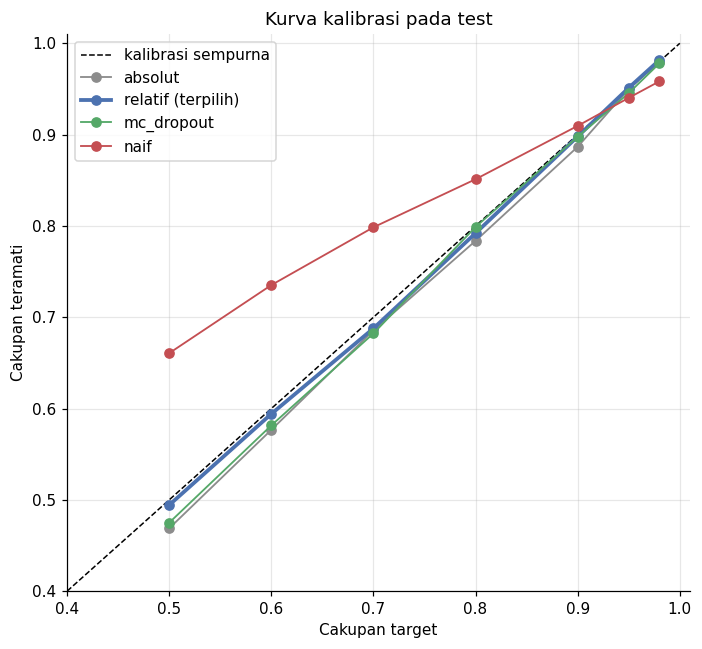

,absolut,relatif,mc_dropout,naif
target,,,,
50%,0.469,0.494,0.475,0.661
60%,0.577,0.594,0.582,0.735
70%,0.686,0.688,0.682,0.799
80%,0.784,0.792,0.799,0.851
90%,0.887,0.898,0.898,0.910
95%,0.950,0.951,0.945,0.940
98%,0.980,0.982,0.978,0.958


In [7]:
ALPHAS = [0.5, 0.4, 0.3, 0.2, 0.1, 0.05, 0.02]
curve = {k: [] for k in METHODS + ["naif"]}
for a in ALPHAS:
    for k, (lo, hi) in intervals_on_test(a).items():
        curve[k].append(float(np.mean((yt >= lo) & (yt <= hi))))

target_cov = [1 - a for a in ALPHAS]
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0.4, 1], [0.4, 1], "k--", lw=1, label="kalibrasi sempurna")
styles = {"absolut": "#8C8C8C", "relatif": "#4C72B0", "mc_dropout": "#55A868", "naif": "#C44E52"}
for k, v in curve.items():
    ax.plot(target_cov, v, "o-", color=styles.get(k, "k"), lw=2.5 if k == CHOSEN else 1.2, label=k + (" (terpilih)" if k == CHOSEN else ""))
ax.set(title="Kurva kalibrasi pada test", xlabel="Cakupan target", ylabel="Cakupan teramati", xlim=(0.4, 1.01), ylim=(0.4, 1.01))
ax.legend(loc="upper left")
plt.tight_layout()
save_fig("19_kalibrasi_interval")
plt.show()

display(pd.DataFrame(curve, index=[f"{int(t * 100)}%" for t in target_cov]).round(3).rename_axis("target"))

### 4.3 Cakupan per kelompok

Jaminan conformal hanya untuk **cakupan rata-rata**. Pengguna aplikasi tidak peduli rata-rata: mereka peduli apakah rentang untuk
*rumah mereka* bisa dipercaya. Maka cakupan diperiksa per kelompok harga prediksi, per kategori lokasi, dan pada blok bertarget terpotong.

> Kategori `ISLAND` hanya berisi **1 blok** di test, jadi cakupannya (0% atau 100%) tidak bisa ditafsirkan secara statistik.

In [8]:
raw = pd.read_csv(DATA_PATH).dropna(subset=[TARGET, "ocean_proximity"])
shuffled = raw.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
n_all = len(shuffled)
n_tr, n_va = int(n_all * 0.70), int(n_all * 0.15)
test_df = shuffled.iloc[n_tr + n_va:].reset_index(drop=True)
assert np.allclose(test_df[TARGET].to_numpy("float64"), yt), "Urutan test tidak cocok dengan notebook 02"

grp_t = pd.cut(pt, BIN_EDGES, labels=BIN_LABELS)
capped = (test_df[TARGET].to_numpy() == test_df[TARGET].max())


def cov_by(groups, order=None):
    out = {}
    for m, (lo, hi) in IV.items():
        hit = pd.Series((yt >= lo) & (yt <= hi))
        out[m] = hit.groupby(np.asarray(groups)).mean()
    t = pd.DataFrame(out)
    t.insert(0, "jumlah", pd.Series(np.asarray(groups)).value_counts())
    return t.loc[order] if order is not None else t


by_pred = cov_by(grp_t, BIN_LABELS)
by_ocean = cov_by(test_df["ocean_proximity"].to_numpy())
by_cap = cov_by(np.where(capped, "terpotong ($500.001)", "tidak terpotong"))

print(f"Cakupan per kelompok HARGA PREDIKSI (target {int((1 - ALPHA) * 100)}%):")
display(by_pred.round(3))
print("Cakupan per kategori lokasi:")
display(by_ocean.round(3))
print("Cakupan pada blok bertarget terpotong vs tidak:")
display(by_cap.round(3))

Cakupan per kelompok HARGA PREDIKSI (target 90%):


,jumlah,absolut,relatif,mc_dropout,naif
<100k,443,0.986,0.874,0.948,0.989
100-200k,1295,0.948,0.898,0.922,0.959
200-300k,826,0.834,0.886,0.852,0.863
300-400k,337,0.694,0.905,0.828,0.748
>=400k,196,0.806,0.990,0.934,0.878


Cakupan per kategori lokasi:


,jumlah,absolut,relatif,mc_dropout,naif
<1H OCEAN,1416,0.868,0.907,0.864,0.896
INLAND,978,0.953,0.885,0.945,0.960
ISLAND,1,0.000,1.000,1.000,0.000
NEAR BAY,341,0.845,0.889,0.889,0.877
NEAR OCEAN,361,0.823,0.906,0.909,0.859


Cakupan pada blok bertarget terpotong vs tidak:


,jumlah,absolut,relatif,mc_dropout,naif
terpotong ($500.001),153,0.673,0.889,0.810,0.719
tidak terpotong,2944,0.898,0.898,0.902,0.919


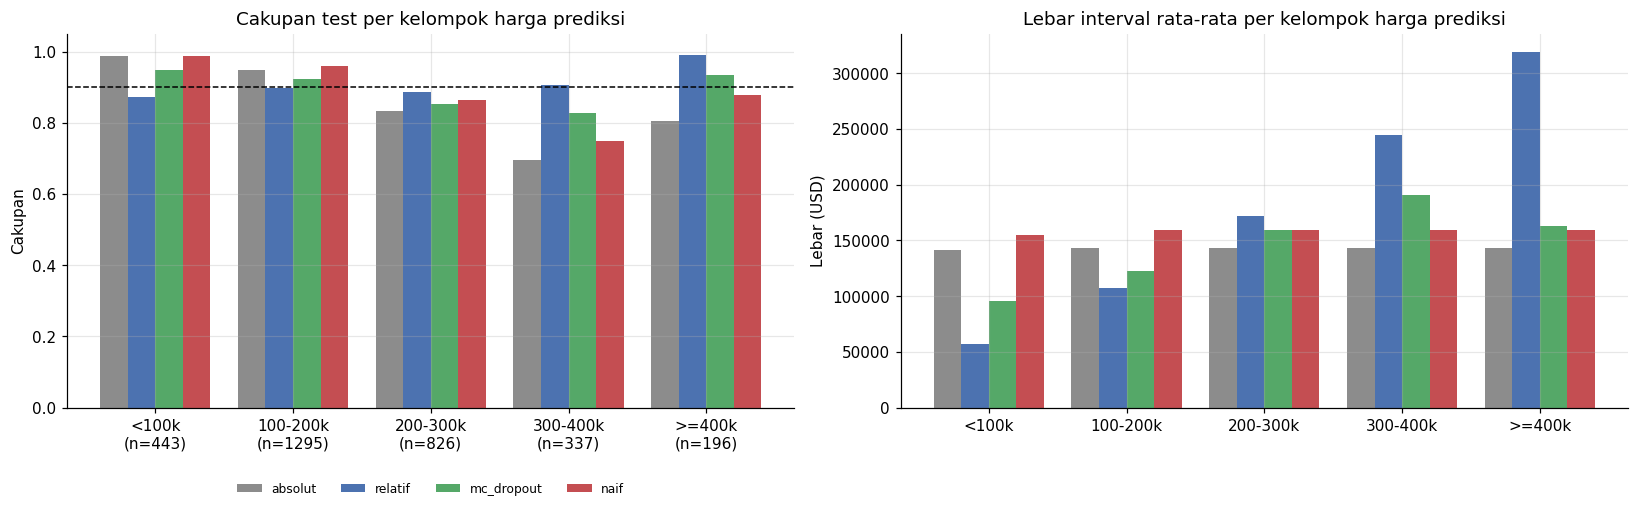

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(BIN_LABELS)); methods_plot = METHODS + ["naif"]; w = 0.8 / len(methods_plot)
for i, m in enumerate(methods_plot):
    ax[0].bar(x + i * w - 0.4 + w / 2, by_pred[m].to_numpy(), w, label=m, color=styles.get(m, "k"))
ax[0].axhline(1 - ALPHA, color="black", ls="--", lw=1)
ax[0].set_xticks(x, [f"{l}\n(n={int(n)})" for l, n in zip(BIN_LABELS, by_pred["jumlah"])])
ax[0].set(title="Cakupan test per kelompok harga prediksi", ylabel="Cakupan", ylim=(0, 1.05))
ax[0].legend(fontsize=8, ncol=len(methods_plot), loc="upper center", bbox_to_anchor=(0.5, -0.17), frameon=False)

wid = {}
for m, (lo, hi) in IV.items():
    wid[m] = pd.Series(hi - lo).groupby(np.asarray(grp_t)).mean().reindex(BIN_LABELS)
for i, m in enumerate(methods_plot):
    ax[1].bar(x + i * w - 0.4 + w / 2, wid[m].to_numpy(), w, label=m, color=styles.get(m, "k"))
ax[1].set_xticks(x, BIN_LABELS)
ax[1].set(title="Lebar interval rata-rata per kelompok harga prediksi", ylabel="Lebar (USD)")
plt.tight_layout()
save_fig("20_cakupan_per_kelompok")
plt.show()

### 4.4 Kestabilan: pembagian ulang acak

Satu pembagian validation/test menghasilkan satu angka cakupan. Untuk melihat seberapa stabil, data validation dan test
**digabung** (6.193 blok), lalu dibagi ulang secara acak `N_REPEAT` kali dengan ukuran kalibrasi yang sama. Prediksi model tidak
berubah, hanya pembagian kalibrasi/uji. Teori split conformal memperkirakan rata-rata cakupan `≥` target dengan sebaran yang sempit.

> **Catatan:** validation dipakai Keras untuk *early stopping*, jadi data gabungan tidak sepenuhnya bebas dari proses pelatihan.
> Uji ini mengukur kestabilan prosedur kalibrasi, bukan menggantikan hasil di test pada 4.1.

,rata2,std,persentil5,persentil95,min,proporsi_di_bawah_target
absolut,0.901,0.008,0.889,0.913,0.881,0.445
relatif,0.901,0.007,0.888,0.912,0.881,0.460
mc_dropout,0.901,0.008,0.888,0.913,0.879,0.490
naif,0.914,0.006,0.905,0.924,0.896,0.015


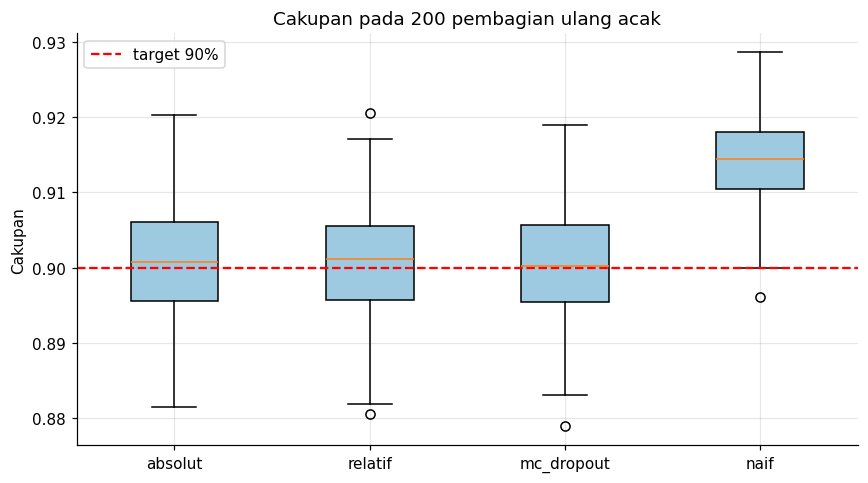

In [10]:
pool_y, pool_p = np.concatenate([yv, yt]), np.concatenate([pv, pt])
pool_s = np.concatenate([SIG["val"], SIG["test"]]) if RUN_MC else None
n_cal = len(yv)
rng = np.random.default_rng(SEED)
rep = {k: [] for k in METHODS + ["naif"]}
for _ in range(N_REPEAT):
    idx = rng.permutation(len(pool_y))
    c, t = idx[:n_cal], idx[n_cal:]
    for m in METHODS:
        sc = pool_s[c] if pool_s is not None else None
        st = pool_s[t] if pool_s is not None else None
        q = conformal_q(scores_of(m, pool_y[c], pool_p[c], sc), ALPHA)
        lo, hi = make_interval(m, q, pool_p[t], st)
        rep[m].append(np.mean((pool_y[t] >= lo) & (pool_y[t] <= hi)))
    rm = np.sqrt(np.mean((pool_p[c] - pool_y[c]) ** 2)); z = NormalDist().inv_cdf(1 - ALPHA / 2)
    rep["naif"].append(np.mean((pool_y[t] >= np.maximum(pool_p[t] - z * rm, 0)) & (pool_y[t] <= pool_p[t] + z * rm)))

stab = pd.DataFrame({k: {"rata2": np.mean(v), "std": np.std(v, ddof=1), "persentil5": np.percentile(v, 5),
                         "persentil95": np.percentile(v, 95), "min": np.min(v),
                         "proporsi_di_bawah_target": np.mean(np.array(v) < 1 - ALPHA)} for k, v in rep.items()}).T
display(stab.round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([rep[k] for k in rep], patch_artist=True, boxprops={"facecolor": "#9ecae1"})
ax.set_xticks(range(1, len(rep) + 1), list(rep))
ax.axhline(1 - ALPHA, color="red", ls="--", label=f"target {int((1 - ALPHA) * 100)}%")
ax.set(title=f"Cakupan pada {N_REPEAT} pembagian ulang acak", ylabel="Cakupan"); ax.legend()
plt.tight_layout()
save_fig("21_kestabilan_cakupan")
plt.show()

### 4.5 Contoh interval

60 blok test yang dipilih acak, diurutkan menurut prediksi. Titik hijau = harga sebenarnya yang **tercakup**, titik merah = **meleset**.

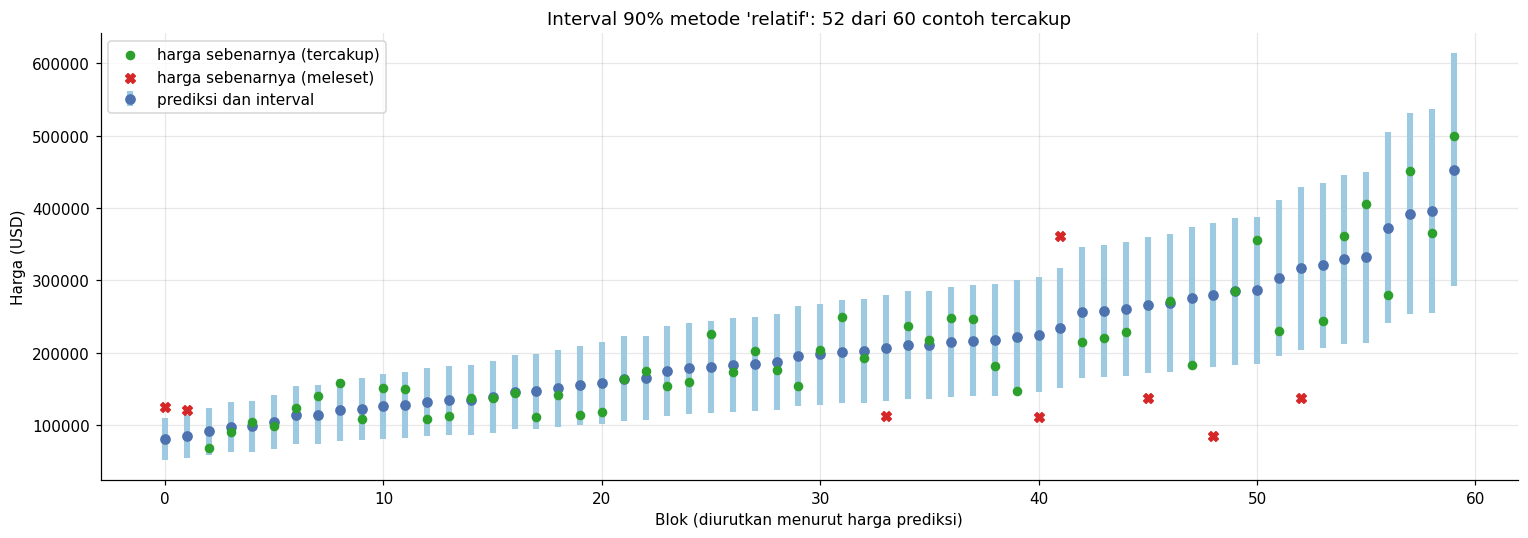

In [11]:
lo_c, hi_c = IV[CHOSEN]
pick = np.sort(np.random.default_rng(SEED).choice(len(pt), 60, replace=False))
pick = pick[np.argsort(pt[pick])]
hit = (yt[pick] >= lo_c[pick]) & (yt[pick] <= hi_c[pick])

fig, ax = plt.subplots(figsize=(14, 5))
xs = np.arange(len(pick))
ax.errorbar(xs, pt[pick], yerr=[pt[pick] - lo_c[pick], hi_c[pick] - pt[pick]], fmt="o", color="#4C72B0", ecolor="#9ecae1",
            elinewidth=4, capsize=0, label="prediksi dan interval")
ax.scatter(xs[hit], yt[pick][hit], color="#2ca02c", zorder=3, s=28, label="harga sebenarnya (tercakup)")
ax.scatter(xs[~hit], yt[pick][~hit], color="#d62728", zorder=3, s=40, marker="X", label="harga sebenarnya (meleset)")
ax.set(title=f"Interval {int((1 - ALPHA) * 100)}% metode '{CHOSEN}': {int(hit.sum())} dari {len(pick)} contoh tercakup",
       xlabel="Blok (diurutkan menurut harga prediksi)", ylabel="Harga (USD)")
ax.legend(loc="upper left")
plt.tight_layout()
save_fig("22_contoh_interval")
plt.show()

## 5. Penyimpanan dan Integrasi ke Aplikasi

Parameter kalibrasi disimpan ke `data/processed/conformal.json`, termasuk **SHA-256 model** yang dipakai kalibrasi. Nilai `q` hanya sah untuk
model yang sama persis; jika aplikasi memakai model lain, kalibrasi harus diulang. Fungsi `interval_from_conf` di bawah adalah yang
disalin ke `backend/` (tidak memerlukan Keras untuk metode `absolut` dan `relatif`).

In [12]:
def interval_from_conf(y_hat_usd, conf, alpha="0.1", sigma_usd=None):
    # Hitung (bawah, atas) dalam USD dari prediksi y_hat_usd. Salin fungsi ini ke backend/app.py.
    q = conf["q"][alpha]
    if conf["metode"] == "absolut":
        half = q
    elif conf["metode"] == "relatif":
        half = q * max(y_hat_usd, conf["floor_usd"])
    elif conf["metode"] == "mc_dropout":
        half = q * (sigma_usd + conf["mc"]["eps_usd"])
    else:
        raise ValueError(conf["metode"])
    return max(y_hat_usd - half, 0.0), y_hat_usd + half


SAVE_ALPHAS = [0.2, 0.1, 0.05]
conf = {
    "fitur": "interval prediksi (split conformal prediction)", "tanggal": str(date.today()),
    "metode": CHOSEN, "alpha_utama": ALPHA, "n_kalibrasi": int(len(yv)),
    "q": {str(a): conformal_q(scores_of(CHOSEN, yv, pv, SIG["val"]), a) for a in SAVE_ALPHAS},
    "floor_usd": FLOOR, "mc": {"T": MC_T, "eps_usd": EPS_MC} if CHOSEN == "mc_dropout" else None,
    "model_sumber": model_key, "model_file": str(Path(model_path).relative_to(ROOT)), "model_sha256": model_sha,
    "cakupan_test": {"alpha": ALPHA, "cakupan": float(cmp_tbl.loc[CHOSEN + " (TERPILIH)", "cakupan_test"]),
                     "lebar_rata2_usd": float(cmp_tbl.loc[CHOSEN + " (TERPILIH)", "lebar_rata2_USD"])},
    "catatan": "q hanya valid untuk model dengan SHA-256 di atas. Jaminan berlaku untuk cakupan rata-rata, bukan per kelompok.",
}
(MODEL_DIR / "conformal.json").write_text(json.dumps(conf, indent=2))

# Verifikasi: fungsi integrasi (dari JSON) harus menghasilkan interval yang IDENTIK dengan yang dipakai pada evaluasi
conf_loaded = json.loads((MODEL_DIR / "conformal.json").read_text())
sig_t = SIG["test"] if SIG["test"] is not None else [None] * len(pt)
manual = np.array([interval_from_conf(p, conf_loaded, str(ALPHA), s) for p, s in zip(pt, sig_t)])
print("Interval dari JSON == interval evaluasi (bawah):", np.allclose(manual[:, 0], IV[CHOSEN][0]))
print("Interval dari JSON == interval evaluasi (atas) :", np.allclose(manual[:, 1], IV[CHOSEN][1]))
assert np.allclose(manual[:, 0], IV[CHOSEN][0]) and np.allclose(manual[:, 1], IV[CHOSEN][1])

print("\nContoh penggunaan:")
for p in (150_000.0, 300_000.0, 450_000.0):
    s_ = float(np.median(SIG["val"])) if CHOSEN == "mc_dropout" else None
    lo, hi = interval_from_conf(p, conf_loaded, str(ALPHA), s_)
    print(f"  prediksi ${p:>9,.0f}  ->  rentang {int((1 - ALPHA) * 100)}%: ${lo:>9,.0f} sampai ${hi:>9,.0f}")
print("\nTersimpan:", (MODEL_DIR / "conformal.json").relative_to(ROOT))

Interval dari JSON == interval evaluasi (bawah): True
Interval dari JSON == interval evaluasi (atas) : True

Contoh penggunaan:
  prediksi $  150,000  ->  rentang 90%: $   96,844 sampai $  203,156
  prediksi $  300,000  ->  rentang 90%: $  193,689 sampai $  406,311
  prediksi $  450,000  ->  rentang 90%: $  290,533 sampai $  609,467

Tersimpan: data/processed/conformal.json


**Cara memasangnya di aplikasi** (belum dilakukan di notebook ini, agar `backend/` tidak berubah tanpa Anda sadari):

1. Salin `data/processed/conformal.json` ke `backend/artifacts/` dan fungsi `interval_from_conf` ke `backend/app.py`.
2. Muat JSON saat startup, lalu di endpoint prediksi panggil fungsi itu pada prediksi dalam USD dan sertakan `harga_bawah` dan `harga_atas`
   pada respons.
3. Di `frontend/`, tampilkan rentang di bawah angka utama.
4. **Pastikan model di `backend/artifacts/model.keras` sama dengan yang dikalibrasi.** Bandingkan SHA-256 file model dengan nilai di JSON.
   Bila beda (misalnya model dilatih ulang), jalankan ulang notebook ini.

Jika metode terpilih adalah `mc_dropout`, aplikasi perlu menjalankan `model(x, training=True)` sebanyak `MC_T` kali per permintaan untuk mendapatkan
`sigma_usd`, sehingga lebih lambat dan lebih rumit daripada `absolut` dan `relatif` yang cukup memakai angka prediksi.

## 6. Kesimpulan Otomatis

Sel di bawah menyusun kesimpulan dari angka yang benar-benar dihitung di atas.

In [13]:
ch = cmp_tbl.loc[CHOSEN + " (TERPILIH)"]
nv = cmp_tbl.loc["naif"]
inside = ch["CI95_bawah"] <= 1 - ALPHA <= ch["CI95_atas"]
s_ch = stab.loc[CHOSEN]
worst_bin = by_pred[CHOSEN].idxmin()
L = [f"**Interval prediksi {int((1 - ALPHA) * 100)}% (metode `{CHOSEN}`, model `{model_key}`)**", ""]
L += [f"- **Cakupan test: {ch['cakupan_test'] * 100:.1f}%** (selang kepercayaan 95%: {ch['CI95_bawah'] * 100:.1f}% sampai {ch['CI95_atas'] * 100:.1f}%) "
      f"terhadap target {int((1 - ALPHA) * 100)}%. "
      + ("Target berada di dalam selang, jadi cakupannya sesuai jaminan." if inside
         else ("Cakupan **melampaui** target (konservatif)." if ch["CI95_bawah"] > 1 - ALPHA
               else "Cakupan **di bawah** target secara signifikan; periksa kembali asumsi pertukaran data (lihat keterbatasan)."))]
L += [f"- Lebar rata-rata **${ch['lebar_rata2_USD']:,.0f}** (median ${ch['lebar_median_USD']:,.0f}); lebar median relatif {ch['lebar_relatif_median'] * 100:.0f}% dari harga prediksi."]
L += [f"- Pembanding naif (`± 1,645 × RMSE`): cakupan {nv['cakupan_test'] * 100:.1f}%, lebar rata-rata ${nv['lebar_rata2_USD']:,.0f}. "
      f"Conformal memberi lebar rata-rata {'lebih sempit' if ch['lebar_rata2_USD'] < nv['lebar_rata2_USD'] else 'lebih lebar'} "
      f"(${ch['lebar_rata2_USD']:,.0f} vs ${nv['lebar_rata2_USD']:,.0f}) dengan cakupan terkalibrasi, sedangkan interval naif tidak punya jaminan."]
L += [f"- Kestabilan ({N_REPEAT} pembagian ulang): rata-rata cakupan {s_ch['rata2'] * 100:.1f}%, simpangan baku {s_ch['std'] * 100:.2f} poin, "
      f"rentang 5% sampai 95%: {s_ch['persentil5'] * 100:.1f}% sampai {s_ch['persentil95'] * 100:.1f}%."]
L += [f"- Cakupan per kelompok harga prediksi berkisar **{by_pred[CHOSEN].min() * 100:.1f}% sampai {by_pred[CHOSEN].max() * 100:.1f}%** "
      f"(terendah pada kelompok `{worst_bin}`), sedangkan interval naif berkisar {by_pred['naif'].min() * 100:.1f}% sampai {by_pred['naif'].max() * 100:.1f}%."]
cap_row = by_cap.loc["terpotong ($500.001)", CHOSEN] if "terpotong ($500.001)" in by_cap.index else float("nan")
L += [f"- Pada blok bertarget terpotong di \\$500.001 cakupan **{cap_row * 100:.1f}%**; nilai aslinya tidak diketahui sehingga angka ini harus dibaca hati-hati."]
L += ["", "**Keterbatasan**",
      "1. Jaminan berlaku untuk cakupan **rata-rata**, bukan untuk setiap kelompok; kelompok dengan cakupan di bawah target tampak di bagian 4.3.",
      "2. Mengandaikan data baru **sebaran sama** dengan data kalibrasi. Data ini dari sensus 1990, dan input aplikasi di luar rentang data tidak tercakup jaminannya.",
      "3. Validation dipakai Keras untuk *early stopping* sebelum dipakai kalibrasi, sehingga ada ketergantungan kecil; cakupan di test (4.1) adalah pengujian bebasnya.",
      "4. Nilai `q` hanya sah untuk model dengan SHA-256 yang tercatat di `conformal.json`."]
display(Markdown("\n".join(L)))

**Interval prediksi 90% (metode `relatif`, model `backend`)**

- **Cakupan test: 89.8%** (selang kepercayaan 95%: 88.7% sampai 90.9%) terhadap target 90%. Target berada di dalam selang, jadi cakupannya sesuai jaminan.
- Lebar rata-rata **$145,836** (median $132,176); lebar median relatif 71% dari harga prediksi.
- Pembanding naif (`± 1,645 × RMSE`): cakupan 91.0%, lebar rata-rata $158,830. Conformal memberi lebar rata-rata lebih sempit ($145,836 vs $158,830) dengan cakupan terkalibrasi, sedangkan interval naif tidak punya jaminan.
- Kestabilan (200 pembagian ulang): rata-rata cakupan 90.1%, simpangan baku 0.75 poin, rentang 5% sampai 95%: 88.8% sampai 91.2%.
- Cakupan per kelompok harga prediksi berkisar **87.4% sampai 99.0%** (terendah pada kelompok `<100k`), sedangkan interval naif berkisar 74.8% sampai 98.9%.
- Pada blok bertarget terpotong di \$500.001 cakupan **88.9%**; nilai aslinya tidak diketahui sehingga angka ini harus dibaca hati-hati.

**Keterbatasan**
1. Jaminan berlaku untuk cakupan **rata-rata**, bukan untuk setiap kelompok; kelompok dengan cakupan di bawah target tampak di bagian 4.3.
2. Mengandaikan data baru **sebaran sama** dengan data kalibrasi. Data ini dari sensus 1990, dan input aplikasi di luar rentang data tidak tercakup jaminannya.
3. Validation dipakai Keras untuk *early stopping* sebelum dipakai kalibrasi, sehingga ada ketergantungan kecil; cakupan di test (4.1) adalah pengujian bebasnya.
4. Nilai `q` hanya sah untuk model dengan SHA-256 yang tercatat di `conformal.json`.